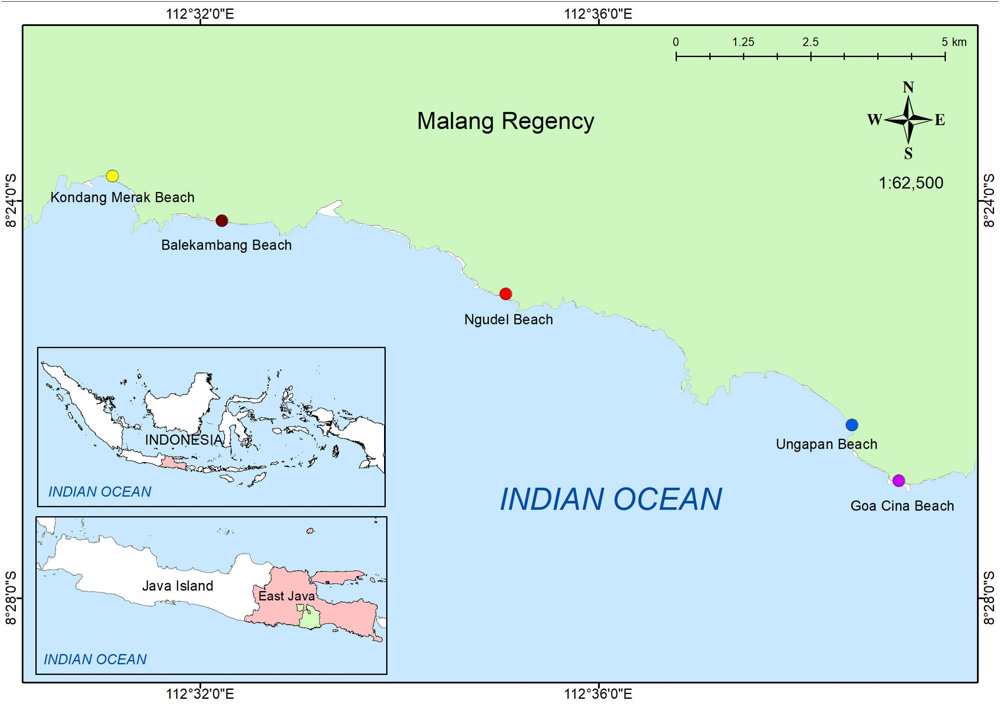

**Batas	Koordinat:**

Barat	112.25° BT

Timur	113.10° BT

Utara	8.35° LS

Selatan	9.15° LS

In [5]:
from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [7]:
import pandas as pd

file_path = '/content/drive/MyDrive/JOINTS/fixdataset.csv'
df = pd.read_csv(file_path)

df.head()

,period,year,month,grid_x,grid_y,longitude,latitude,sst,chlor_a,depth_m,potential_score,potential_label,spot_label,grid_id,easting_m,northing_m,ocean_fraction
0,2024-01,2024,1,149,1,112.926947,-9.147720,29.977,0.2612,5000.0,18.59,rendah,0,X149_Y001,711750,8988250,1.0
1,2024-01,2024,1,150,1,112.931496,-9.147696,29.963,0.2672,5000.0,18.37,rendah,0,X150_Y001,712250,8988250,1.0
2,2024-01,2024,1,151,1,112.936044,-9.147671,29.965,0.2501,5000.0,18.34,rendah,0,X151_Y001,712750,8988250,1.0
3,2024-01,2024,1,152,1,112.940592,-9.147647,29.924,0.2557,5000.0,18.16,rendah,0,X152_Y001,713250,8988250,1.0
4,2024-01,2024,1,153,1,112.945140,-9.147623,29.953,0.2368,5000.0,19.19,rendah,0,X153_Y001,713750,8988250,1.0


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from google.colab import files
from IPython.display import display
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Library berhasil diimpor.")


Library berhasil diimpor.


In [9]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print("Jumlah data :", f"{df.shape[0]:,}")

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\nTipe data setiap kolom:")
display(df.dtypes.to_frame("data_type"))


Jumlah baris : 752496
Jumlah kolom : 17
Jumlah data : 752,496

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 752496 entries, 0 to 752495
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   period           752496 non-null  object 
 1   year             752496 non-null  int64  
 2   month            752496 non-null  int64  
 3   grid_x           752496 non-null  int64  
 4   grid_y           752496 non-null  int64  
 5   longitude        752496 non-null  float64
 6   latitude         752496 non-null  float64
 7   sst              752496 non-null  float64
 8   chlor_a          752496 non-null  float64
 9   depth_m          752496 non-null  float64
 10  potential_score  752496 non-null  float64
 11  potential_label  752496 non-null  object 
 12  spot_label       752496 non-null  int64  
 13  grid_id          752496 non-null  object 
 14  easting_m        752496 non-null  int64  
 15  nor

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
period,752496,24,2024-01,31354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,752496.0,NaN,NaN,NaN,2024.5,0.5,2024.0,2024.0,2024.5,2025.0,2025.0
month,752496.0,NaN,NaN,NaN,6.5,3.452055,1.0,3.75,6.5,9.25,12.0
grid_x,752496.0,NaN,NaN,NaN,94.042259,54.494661,1.0,46.0,94.0,142.0,187.0
grid_y,752496.0,NaN,NaN,NaN,85.654845,48.815526,1.0,43.0,86.0,128.0,177.0
longitude,752496.0,NaN,NaN,NaN,112.675209,0.247626,112.252288,112.457325,112.675656,112.892642,113.097696
latitude,752496.0,NaN,NaN,NaN,-8.766189,0.220686,-9.14772,-8.957247,-8.766203,-8.575962,-8.354465
sst,752496.0,NaN,NaN,NaN,28.574972,0.677481,25.963,28.091,28.623,29.103,30.396
chlor_a,752496.0,NaN,NaN,NaN,0.875198,0.560478,0.0998,0.4569,0.7177,1.1467,5.1405
depth_m,752496.0,NaN,NaN,NaN,2110.391063,1520.068998,18.0,748.1,1840.45,3347.5,5000.0



Tipe data setiap kolom:


,data_type
period,object
year,int64
month,int64
grid_x,int64
grid_y,int64
longitude,float64
latitude,float64
sst,float64
chlor_a,float64
depth_m,float64


In [10]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing)

# Visualisasi missing values
missing_plot = missing[missing["missing_count"] > 0]

if len(missing_plot) > 0:
    ax = missing_plot["missing_percent"].plot(
        kind="bar", figsize=(12, 5)
    )
    ax.set_title("Persentase Missing Values")
    ax.set_ylabel("Missing (%)")
    ax.set_xlabel("Kolom")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada missing values.")


,missing_count,missing_percent,data_type
period,0,0.0,object
year,0,0.0,int64
month,0,0.0,int64
grid_x,0,0.0,int64
grid_y,0,0.0,int64
longitude,0,0.0,float64
latitude,0,0.0,float64
sst,0,0.0,float64
chlor_a,0,0.0,float64
depth_m,0,0.0,float64


Tidak ada missing values.


,count,mean,std,min,25%,50%,75%,max
sst,752496.0,28.574972,0.677481,25.963000,28.091000,28.623000,29.103000,30.396000
chlor_a,752496.0,0.875198,0.560478,0.099800,0.456900,0.717700,1.146700,5.140500
depth_m,752496.0,2110.391063,1520.068998,18.000000,748.100000,1840.450000,3347.500000,5000.000000
potential_score,752496.0,63.790402,18.043834,9.210000,51.500000,67.560000,77.970000,100.000000
ocean_fraction,752496.0,0.999448,0.013024,0.500899,1.000000,1.000000,1.000000,1.000000
longitude,752496.0,112.675209,0.247626,112.252288,112.457325,112.675656,112.892642,113.097696
latitude,752496.0,-8.766189,0.220686,-9.147720,-8.957247,-8.766203,-8.575962,-8.354465


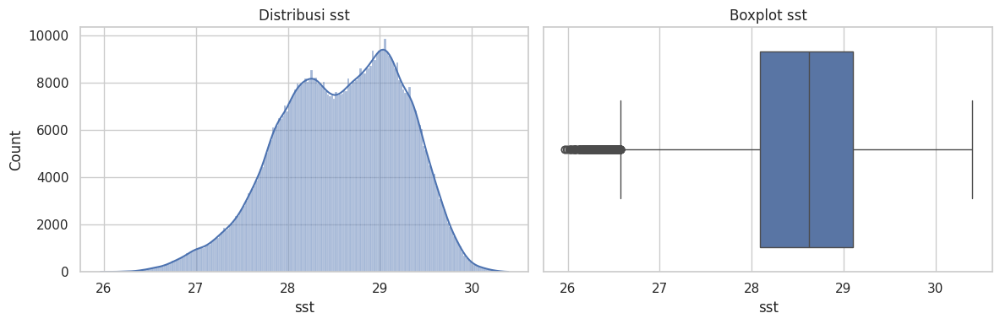

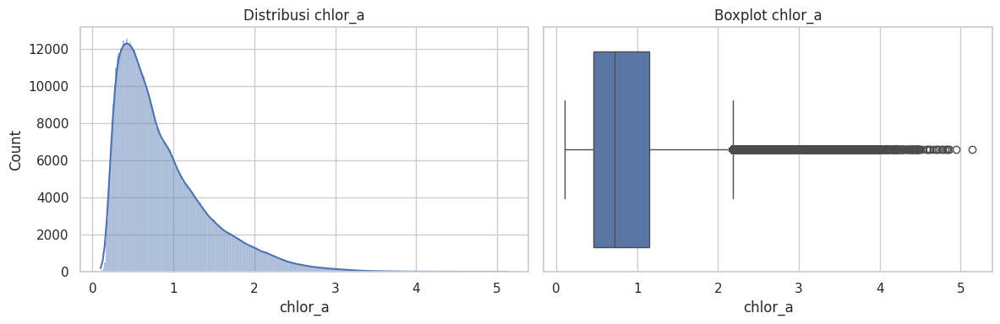

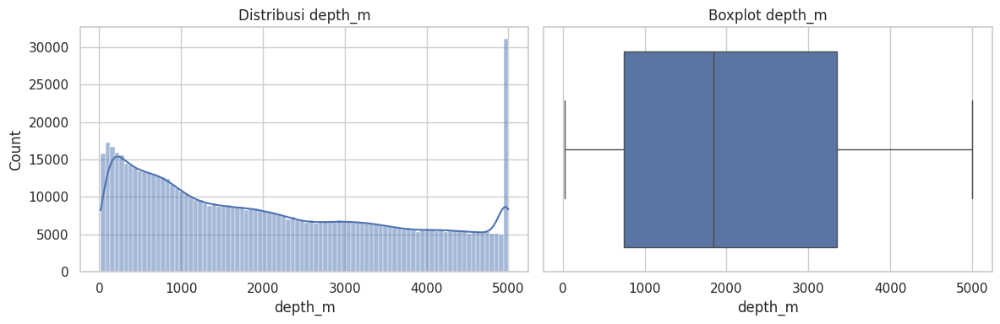

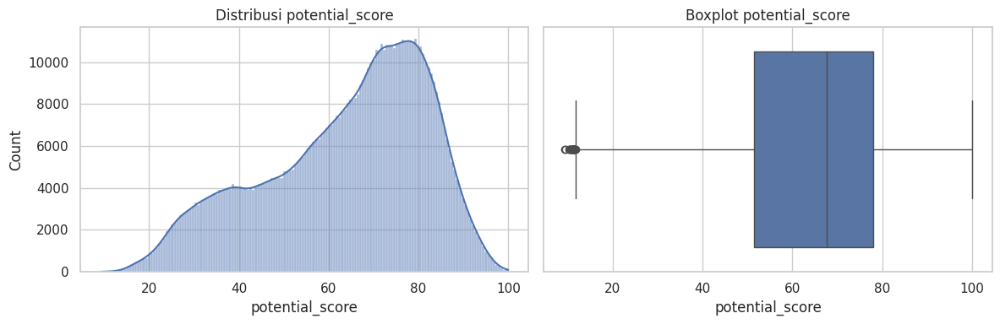

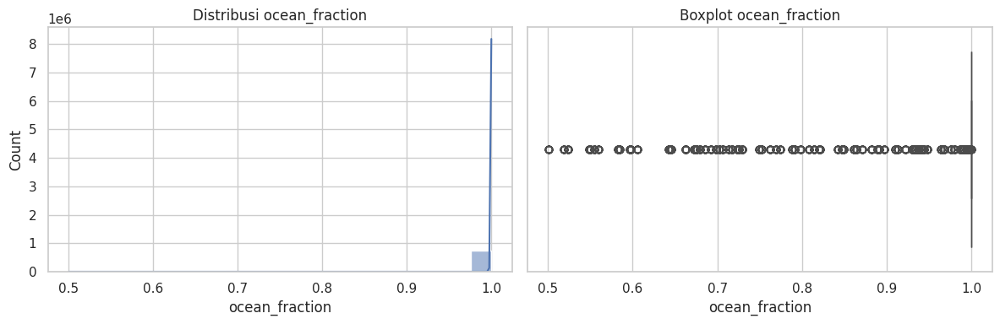

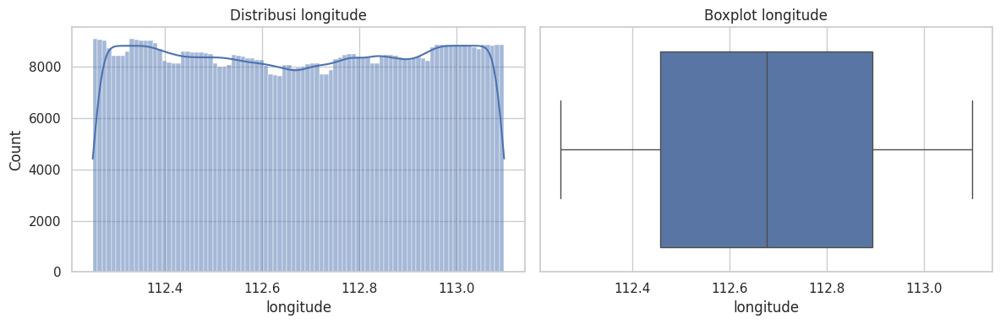

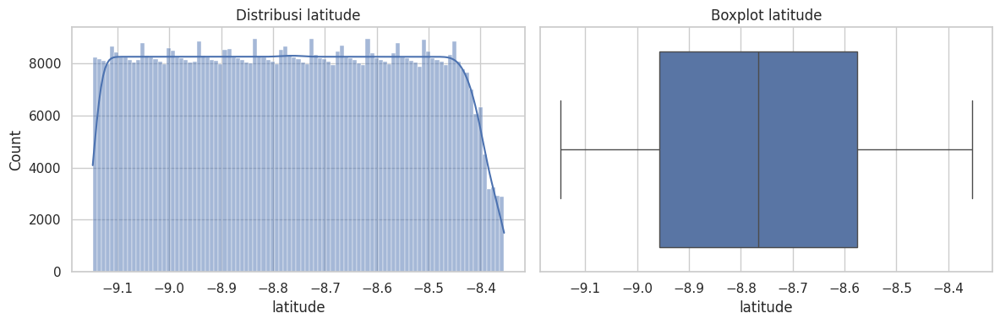

In [11]:

numeric_cols = [
    "sst", "chlor_a", "depth_m",
    "potential_score", "ocean_fraction",
    "longitude", "latitude"
]

numeric_cols = [
    c for c in numeric_cols if c in df.columns
]

display(df[numeric_cols].describe().T)

for col in numeric_cols:
    series = pd.to_numeric(df[col], errors="coerce").dropna()

    if series.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(series, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribusi {col}")

    sns.boxplot(x=series, ax=axes[1])
    axes[1].set_title(f"Boxplot {col}")

    plt.tight_layout()
    plt.show()


In [12]:

geo_cols = [
    "longitude", "latitude", "potential_score"
]

if all(c in df.columns for c in geo_cols):
    geo = df[geo_cols + [
        c for c in ["potential_label", "grid_id", "period"]
        if c in df.columns
    ]].copy()

    geo["longitude"] = pd.to_numeric(
        geo["longitude"], errors="coerce"
    )
    geo["latitude"] = pd.to_numeric(
        geo["latitude"], errors="coerce"
    )
    geo["potential_score"] = pd.to_numeric(
        geo["potential_score"], errors="coerce"
    )

    geo = geo.dropna(
        subset=["longitude", "latitude", "potential_score"]
    )

    max_points = 30000
    if len(geo) > max_points:
        geo = geo.sample(max_points, random_state=42)

    fig = px.scatter_map(
        geo,
        lat="latitude",
        lon="longitude",
        color="potential_score",
        hover_name="grid_id" if "grid_id" in geo.columns else None,
        hover_data=[
            c for c in ["potential_label", "period"]
            if c in geo.columns
        ],
        color_continuous_scale="Viridis",
        zoom=5,
        height=650,
        title="Peta Spasial Skor Potensi Laut"
    )

    fig.update_layout(map_style="open-street-map")
    fig.show()


In [13]:
for col in ["sst", "chlor_a", "depth_m"]:
    if not all(c in df.columns for c in ["longitude", "latitude", col]):
        continue

    temp = df[["longitude", "latitude", col]].copy()

    for c in ["longitude", "latitude", col]:
        temp[c] = pd.to_numeric(temp[c], errors="coerce")

    temp = temp.dropna()

    if len(temp) > 30000:
        temp = temp.sample(30000, random_state=42)

    fig = px.scatter_map(
        temp,
        lat="latitude",
        lon="longitude",
        color=col,
        color_continuous_scale="Viridis",
        zoom=5,
        height=550,
        title=f"Peta Spasial {col}"
    )
    fig.update_layout(map_style="open-street-map")
    fig.show()


In [18]:
import sys, subprocess, importlib.util, io, zipfile, html
from pathlib import Path

packages = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "folium": "folium", "IPython": "ipython"}
missing = [pkg for mod, pkg in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

try:
    from google.colab import files
except ImportError:
    files = None

CSV_PATH = "/content/fixbangetdataset.csv"
OUT = Path("/content/hasil_clustering_5_level")
MAP_PERIOD = None
MAX_MAP_POINTS = 5000
DOWNLOAD = True
SEED = 42
FEATURES = ["sst", "chlor_a", "depth_m"]
LABELS = {1: "Sangat Rendah", 2: "Rendah", 3: "Sedang", 4: "Tinggi", 5: "Sangat Tinggi"}
COLORS = ["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"]
OUT.mkdir(parents=True, exist_ok=True)

path = next((p for p in [Path(CSV_PATH), Path("/mnt/data/dataset1 - dataset1.csv")]
             if p.is_file()), None)
if path is None:
    if files is None:
        raise FileNotFoundError("Isi CSV_PATH dengan lokasi CSV kamu.")
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if len(csv_names) != 1:
        raise ValueError("Pilih tepat satu file CSV dataset.")
    df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]))
else:
    df = pd.read_csv(path)

df.columns = df.columns.str.strip()
required = FEATURES + ["potential_score", "longitude", "latitude", "period", "grid_id"]
if set(required) - set(df.columns):
    raise ValueError(f"Kolom belum tersedia: {sorted(set(required) - set(df.columns))}")
if len(df) < 5:
    raise ValueError("Diperlukan sedikitnya 5 baris data.")

period = pd.to_datetime(df["period"], format="%Y-%m", errors="coerce")
if period.isna().any():
    raise ValueError("Kolom period harus berformat YYYY-MM.")
print(f"Data: {len(df):,} baris, {period.nunique()} bulan. Fitur: {FEATURES}")

raw = df[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
for col in ["chlor_a", "depth_m"]:
    raw.loc[raw[col] < 0, col] = np.nan
if raw.isna().all().any() or raw.isna().all(axis=1).any():
    raise ValueError("Ada fitur kosong total atau baris tanpa fitur valid; periksa sumbernya.")

imputer = SimpleImputer(strategy="median")
X = imputer.fit_transform(raw)
X[:, 1:] = np.log1p(X[:, 1:])
scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)
if np.unique(X, axis=0).shape[0] < 5:
    raise ValueError("Kombinasi fitur unik kurang dari 5; tidak bisa membuat 5 cluster berbeda.")

model = MiniBatchKMeans(n_clusters=5, random_state=SEED, n_init=10,
                       batch_size=8192, max_iter=100,
                       init_size=min(30000, len(X)), reassignment_ratio=0)
cluster = model.fit_predict(X)
if np.unique(cluster).size != 5:
    raise RuntimeError("Model tidak menghasilkan 5 cluster terisi; periksa variasi fitur.")

score = pd.to_numeric(df["potential_score"], errors="coerce").replace([np.inf, -np.inf], np.nan)
ranking = pd.DataFrame({"cluster_id": cluster, "score": score}).groupby("cluster_id")["score"].mean()
if ranking.isna().any() or ranking.nunique() != 5:
    raise ValueError("Rata-rata skor tiap cluster harus tersedia dan berbeda untuk mengurutkan 5 level.")

level_map = {int(cid): level for level, cid in enumerate(ranking.sort_values().index, 1)}
hasil = df.copy()
hasil["cluster_id"] = cluster
hasil["level_cluster"] = pd.Series(cluster).map(level_map).astype("int8")
hasil["label_cluster"] = hasil["level_cluster"].map(LABELS)
hasil["fitur_diimputasi"] = raw.isna().any(axis=1)
assert set(hasil["level_cluster"]) == {1, 2, 3, 4, 5}

profil = (raw.assign(level_cluster=hasil["level_cluster"], score=score)
          .groupby("level_cluster").agg(
              jumlah=("level_cluster", "size"), sst_mean=("sst", "mean"),
              chlor_a_mean=("chlor_a", "mean"), depth_m_mean=("depth_m", "mean"),
              score_mean=("score", "mean"), score_min=("score", "min"), score_max=("score", "max")))
profil.insert(0, "label_cluster", [LABELS[i] for i in profil.index])
profil["persentase"] = 100 * profil["jumlah"] / len(hasil)

bulanan = pd.crosstab(
    period.dt.strftime("%Y-%m"), hasil["level_cluster"]
).reindex(columns=range(1, 6), fill_value=0)
bulanan.index.name = "period"
bulanan.columns = [f"{i}_{LABELS[i].lower().replace(' ', '_')}" for i in range(1, 6)]

display(profil.round(3))
print("Tepat 5 level. Jumlah anggota tidak harus sama; rentang skor dapat tumpang tindih.")

idx = np.random.default_rng(SEED).choice(len(X), min(3000, len(X)), replace=False)
if 1 < np.unique(cluster[idx]).size < len(idx):
    sil = silhouette_score(X[idx], cluster[idx])
    print(f"Silhouette sampel {len(idx):,} baris: {sil:.4f} (lebih tinggi = lebih terpisah).")
else:
    print("Silhouette tidak dihitung: sampel tidak memenuhi syarat.")

geo = hasil.assign(longitude=pd.to_numeric(hasil["longitude"], errors="coerce"),
                   latitude=pd.to_numeric(hasil["latitude"], errors="coerce"),
                   periode_peta=period.dt.strftime("%Y-%m"))
valid_geo = geo["longitude"].between(-180, 180) & geo["latitude"].between(-90, 90)
geo = geo.loc[valid_geo]
print(f"Koordinat tidak valid (tetap diekspor): {(~valid_geo).sum():,} baris.")
export_files = []

if not geo.empty:
    cmap = ListedColormap(COLORS)
    norm = BoundaryNorm(np.arange(0.5, 6.5), cmap.N)
    periods = sorted(geo["periode_peta"].unique())
    ncols = min(4, len(periods))
    nrows = int(np.ceil(len(periods) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.3*nrows),
                             sharex=True, sharey=True, squeeze=False)

    for ax, per in zip(axes.flat, periods):
        part = geo.loc[geo["periode_peta"] == per]
        ax.scatter(part["longitude"], part["latitude"], c=part["level_cluster"],
                   cmap=cmap, norm=norm, s=2, linewidths=0, rasterized=True)
        ax.set_title(per)
        ax.set_aspect(1 / np.cos(np.deg2rad(geo["latitude"].mean())))
    for ax in list(axes.flat)[len(periods):]:
        ax.set_visible(False)

    fig.supxlabel("Longitude (derajat)")
    fig.supylabel("Latitude (derajat)")
    fig.suptitle("5 level cluster oseanografi per bulan — seluruh titik", y=0.995)
    fig.legend(
        handles=[Patch(color=COLORS[i-1], label=f"{i}. {LABELS[i]}") for i in LABELS],
        loc="upper center", bbox_to_anchor=(0.5, 0.975), ncol=5, fontsize=9
    )
    fig.tight_layout(rect=[0.02, 0.02, 1, 0.945])
    png = OUT / "peta_semua_bulan.png"
    fig.savefig(png, dpi=160, bbox_inches="tight")
    plt.show()
    export_files.append(png)

    selected = MAP_PERIOD or periods[-1]
    latest = geo.loc[geo["periode_peta"] == selected]
    if latest.empty:
        raise ValueError(f"MAP_PERIOD tidak tersedia. Pilih salah satu: {periods}")
    points = latest.sample(n=min(MAX_MAP_POINTS, len(latest)), random_state=SEED)

    m = folium.Map(
        location=[latest["latitude"].mean(), latest["longitude"].mean()],
        tiles="OpenStreetMap", zoom_start=9, prefer_canvas=True
    )
    for level, label in LABELS.items():
        layer = folium.FeatureGroup(name=f"{level}. {label}").add_to(m)
        for row in points.loc[points["level_cluster"] == level].itertuples(index=False):
            popup = f"Grid: {html.escape(str(row.grid_id))}<br>{selected}<br>{level}. {label}"
            folium.CircleMarker(
                [row.latitude, row.longitude], radius=3,
                color=COLORS[level-1], fill=True, fill_opacity=0.85,
                weight=0.3, popup=popup
            ).add_to(layer)

    legend = "<br>".join(
        f'<span style="color:{COLORS[i-1]}">&#9632;</span> {i}. {LABELS[i]}'
        for i in LABELS
    )
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;'
        f'padding:12px;border:1px solid #888;font-size:13px">'
        f'<b>Cluster {selected}</b><br>{len(points):,} / {len(latest):,} titik<br>{legend}</div>'
    ))
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([
        [latest["latitude"].min(), latest["longitude"].min()],
        [latest["latitude"].max(), latest["longitude"].max()]
    ])
    map_html = OUT / f"peta_interaktif_{selected}.html"
    m.save(str(map_html))
    display(m)
    export_files.append(map_html)

for name, table, include_index in [
    ("hasil_clustering_5_level.csv", hasil, False),
    ("profil_5_level.csv", profil, True),
    ("jumlah_cluster_per_bulan.csv", bulanan, True),
]:
    target = OUT / name
    table.to_csv(target, index=include_index, encoding="utf-8-sig")
    export_files.append(target)

zip_path = OUT.parent / "hasil_clustering_5_level.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for target in export_files:
        z.write(target, arcname=target.name)

print(f"Selesai. Seluruh {len(hasil):,} baris tersimpan di {zip_path}")
print("Kolom hasil: cluster_id (0–4), level_cluster (1–5), label_cluster, fitur_diimputasi.")
if DOWNLOAD and files is not None:
    files.download(str(zip_path))

Saving fixbangetdataset.csv to fixbangetdataset.csv
Data: 752,496 baris, 24 bulan. Fitur: ['sst', 'chlor_a', 'depth_m']


,label_cluster,jumlah,sst_mean,chlor_a_mean,depth_m_mean,score_mean,score_min,score_max,persentase
level_cluster,,,,,,,,,
1,Sangat Rendah,221029,29.111,0.377,3437.181,40.846,9.21,67.02,29.373
2,Rendah,121653,29.153,0.774,1044.660,65.969,38.72,89.30,16.167
3,Sedang,226481,28.175,0.796,2746.250,71.509,40.69,96.49,30.097
4,Tinggi,64989,28.826,1.255,274.041,75.441,35.70,95.68,8.636
5,Sangat Tinggi,118344,27.609,1.853,519.459,83.234,44.80,100.00,15.727


Tepat 5 level. Jumlah anggota tidak harus sama; rentang skor dapat tumpang tindih.
Silhouette sampel 3,000 baris: 0.3617 (lebih tinggi = lebih terpisah).
Koordinat tidak valid (tetap diekspor): 0 baris.


Selesai. Seluruh 752,496 baris tersimpan di /content/hasil_clustering_5_level.zip
Kolom hasil: cluster_id (0–4), level_cluster (1–5), label_cluster, fitur_diimputasi.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import json
import zipfile
from pathlib import Path
import pandas as pd

EXPORT_DIR = Path("/content/ekspor_backend")

LABELS = {
    1: "Sangat Rendah",
    2: "Rendah",
    3: "Sedang",
    4: "Tinggi",
    5: "Sangat Tinggi",
}
COLORS = {
    1: "#440154",
    2: "#3b528b",
    3: "#21918c",
    4: "#5ec962",
    5: "#fde725",
}

if "hasil" not in globals():
    raise NameError("Jalankan cell clustering dahulu agar variabel hasil tersedia.")

required = ["grid_id", "period", "longitude", "latitude", "level_cluster"]
missing = sorted(set(required) - set(hasil.columns))
if missing:
    raise ValueError(f"Kolom belum tersedia: {missing}")

data = hasil.copy()
data["level_cluster"] = pd.to_numeric(data["level_cluster"], errors="coerce")

if not data["level_cluster"].isin(LABELS).all():
    raise ValueError("level_cluster harus berupa bilangan bulat 1 sampai 5.")
if set(data["level_cluster"].unique()) != set(LABELS):
    raise ValueError("Hasil clustering harus memiliki tepat lima level terisi.")

data["level_cluster"] = data["level_cluster"].astype(int)
data["label_cluster"] = data["level_cluster"].map(LABELS)

dates = pd.to_datetime(data["period"], format="%Y-%m", errors="coerce")
if dates.isna().any() or data["grid_id"].isna().any():
    raise ValueError("period harus YYYY-MM dan grid_id tidak boleh kosong.")

data["period"] = dates.dt.strftime("%Y-%m")
data["grid_id"] = data["grid_id"].astype(str)

if data.duplicated(["period", "grid_id"]).any():
    raise ValueError("Ada duplikat pasangan period dan grid_id.")

for col in ["longitude", "latitude"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

valid = (
    data["longitude"].between(-180, 180)
    & data["latitude"].between(-90, 90)
)
invalid_count = int((~valid).sum())
data = data.loc[valid].copy()

if data.empty:
    raise ValueError("Tidak ada koordinat valid untuk diekspor.")

# 2. Metadata untuk filter bulan, legenda, dan warna di frontend
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

metadata = {
    "schema_version": 1,
    "geometry_type": "Point",
    "coordinate_reference_system": "WGS84",
    "coordinate_order": ["longitude", "latitude"],
    "total_source_rows": int(len(hasil)),
    "total_exported_points": int(len(data)),
    "invalid_coordinate_rows": invalid_count,
    "label_basis": (
        "Urutan rata-rata potential_score tiap cluster; "
        "level relatif terhadap dataset."
    ),
    "levels": [
        {"level": i, "label": LABELS[i], "color": COLORS[i]}
        for i in LABELS
    ],
    "periods": [],
}

properties = [
    col for col in [
        "grid_id", "period", "cluster_id", "level_cluster",
        "label_cluster", "potential_score", "sst",
        "chlor_a", "depth_m", "fitur_diimputasi",
    ]
    if col in data.columns
]

exported_files = []

for period_name, group in data.groupby("period", sort=True):
    records = json.loads(
        group[properties].to_json(orient="records", double_precision=10)
    )

    features = []
    coordinates = group[["longitude", "latitude"]].itertuples(
        index=False, name=None
    )

    for (longitude, latitude), prop in zip(coordinates, records):
        features.append({
            "type": "Feature",
            "id": f"{period_name}:{prop['grid_id']}",
            "geometry": {
                "type": "Point",
                "coordinates": [float(longitude), float(latitude)],
            },
            "properties": prop,
        })

    bbox = [
        float(group["longitude"].min()),
        float(group["latitude"].min()),
        float(group["longitude"].max()),
        float(group["latitude"].max()),
    ]

    filename = f"clusters_{period_name}.geojson"
    target = EXPORT_DIR / filename

    with target.open("w", encoding="utf-8") as f:
        json.dump(
            {
                "type": "FeatureCollection",
                "bbox": bbox,
                "features": features,
            },
            f,
            ensure_ascii=False,
            allow_nan=False,
            separators=(",", ":"),
        )

    exported_files.append(target)
    metadata["periods"].append({
        "period": str(period_name),
        "file": filename,
        "count": len(features),
        "bbox": bbox,
    })

metadata_path = EXPORT_DIR / "metadata.json"
with metadata_path.open("w", encoding="utf-8") as f:
    json.dump(
        metadata, f, ensure_ascii=False, allow_nan=False, indent=2
    )
exported_files.append(metadata_path)

zip_path = EXPORT_DIR.parent / "geojson_backend.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for target in exported_files:
        z.write(target, arcname="backend/" + target.name)

print(f"Berhasil: {len(metadata['periods'])} bulan, {len(data):,} titik lengkap.")
print(f"Koordinat tidak valid yang dilewati: {invalid_count:,}")
print(f"File ZIP: {zip_path}")

try:
    from google.colab import files
except ImportError:
    print("Unduh ZIP dari lokasi di atas.")
else:
    files.download(str(zip_path))

Berhasil: 24 bulan, 752,496 titik lengkap.
Koordinat tidak valid yang dilewati: 0
File ZIP: /content/geojson_backend.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd

SST_OPT = 29.5
SST_TOL = 2.0

CHL_OPT = 0.28
CHL_TOL = 0.15

df["S_sst"] = np.maximum(
    0,
    1 - np.abs(df["sst"] - SST_OPT) / SST_TOL
)

df["S_chl"] = np.maximum(
    0,
    1 - np.abs(df["chlor_a"] - CHL_OPT) / CHL_TOL
)

df["ZPI"] = 100 * (
    0.5 * df["S_sst"] +
    0.5 * df["S_chl"]
)

print(df[["sst", "chlor_a", "S_sst", "S_chl", "ZPI"]].head())

print("\nStatistik ZPI:")
print(df["ZPI"].describe())


      sst  chlor_a   S_sst     S_chl        ZPI
0  29.977   0.2612  0.7615  0.874667  81.808333
1  29.963   0.2672  0.7685  0.914667  84.158333
2  29.965   0.2501  0.7675  0.800667  78.408333
3  29.924   0.2557  0.7880  0.838000  81.300000
4  29.953   0.2368  0.7735  0.712000  74.275000

Statistik ZPI:
count    752496.000000
mean         32.822882
std          23.442305
min           0.000000
25%          15.025000
50%          29.400000
75%          45.300000
max          99.766667
Name: ZPI, dtype: float64


In [ ]:

import plotly.express as px

fig = px.scatter(
    df,
    x="grid_x",
    y="grid_y",
    color="ZPI",
    color_continuous_scale="YlOrRd",
    range_color=[0, 100],
    hover_data=["sst", "chlor_a", "ZPI"],
    title="Heatmap Zona Potensi Ikan (ZPI)",
    labels={
        "grid_x": "Grid X",
        "grid_y": "Grid Y",
        "ZPI": "Skor ZPI"
    }
)

fig.update_traces(marker=dict(size=8, opacity=0.9))

fig.update_layout(
    template="plotly_white",
    width=900,
    height=650,
    coloraxis_colorbar=dict(title="ZPI (0–100)")
)

fig.show()


In [ ]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df["cell_id"] = (
    df["grid_x"].astype(str) + "_" +
    df["grid_y"].astype(str)
)

df = df.drop_duplicates(
    subset=["cell_id", "period"]
).copy()

# 3. Periksa fitur
required = [
    "sst",
    "chlor_a",
    "depth_m",
    "bottom_slope_deg"
]

df = df.dropna(subset=required)
df = df[
    (df["chlor_a"] > 0) &
    (df["depth_m"] > 0)
].copy()

df["log_chl"] = np.log1p(df["chlor_a"])
df["log_depth"] = np.log1p(df["depth_m"])

experiments = {
    "E0": ["sst", "log_chl"],
    "E1": ["sst", "log_chl", "log_depth"],
    "E2": [
        "sst", "log_chl",
        "log_depth", "bottom_slope_deg"
    ]
}

results = []

for name, features in experiments.items():

    scaler = StandardScaler()
    X = scaler.fit_transform(df[features])

    for k in range(2, 7):

        if len(X) <= k:
            continue

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X)

        score = silhouette_score(
            X,
            labels,
            sample_size=min(5000, len(X)),
            random_state=42
        )

        results.append({
            "experiment": name,
            "k": k,
            "silhouette": score
        })

scores = pd.DataFrame(results)
print(
    scores.sort_values(
        "silhouette",
        ascending=False
    )
)

best = scores.sort_values(
    "silhouette",
    ascending=False
).iloc[0]

features = experiments[best["experiment"]]

X = StandardScaler().fit_transform(
    df[features]
)

model = KMeans(
    n_clusters=int(best["k"]),
    random_state=42,
    n_init=20
)

df["cluster"] = model.fit_predict(X)

print(
    df.groupby("cluster")[required]
      .median()
)

# 9. Simpan hasil
df.to_csv(
    "hasil_cluster_malang.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

required = [
    "sst", "chlor_a", "depth_m",
    "bottom_slope_deg", "grid_x", "grid_y"
]

df = df.dropna(subset=required).copy()
df = df[
    (df["chlor_a"] > 0) &
    (df["depth_m"] > 0)
].copy()

df["log_chl"] = np.log1p(df["chlor_a"])

features = ["sst", "log_chl"]

scaler = StandardScaler()
X = scaler.fit_transform(df[features])

model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

df["cluster"] = model.fit_predict(X)

print("Jumlah data:", len(df))
print("\nJumlah anggota tiap cluster:")
print(df["cluster"].value_counts().sort_index())


In [ ]:

import plotly.express as px

fig = px.scatter(
    df,
    x="grid_x",
    y="grid_y",
    color=df["cluster"].astype(str),
    color_discrete_sequence=["#2878B5", "#F28E2B"],
    title="Peta Sebaran Hasil Clustering Laut Malang",
    labels={
        "grid_x": "Longitude / Grid X",
        "grid_y": "Latitude / Grid Y",
        "color": "Cluster"
    },
    hover_data=[
        "sst", "chlor_a", "depth_m",
        "bottom_slope_deg"
    ]
)

fig.update_traces(
    marker=dict(size=6, opacity=0.8)
)

fig.update_layout(
    template="plotly_white",
    width=900,
    height=650
)

fig.show()


In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

if "cluster" in df.columns:
    print(
        df.groupby("cluster")["ZPI"]
          .agg(["count", "mean", "median", "std"])
          .round(3)
    )

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="cluster",
        y="ZPI"
    )

    plt.title("Distribusi Skor ZPI pada Setiap Cluster")
    plt.xlabel("Cluster K-Means")
    plt.ylabel("Skor ZPI (0–100)")
    plt.tight_layout()
    plt.show()
else:
    print("Jalankan clustering E0 terlebih dahulu.")


In [ ]:

profile = df.groupby("cluster")[
    ["sst", "chlor_a", "depth_m", "bottom_slope_deg"]
].median()

profile_scaled = (
    profile - profile.mean(axis=0)
) / profile.std(axis=0).replace(0, 1)

plt.figure(figsize=(10, 4))

sns.heatmap(
    profile_scaled.T,
    annot=profile.T,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Nilai relatif terstandardisasi"}
)

plt.title("Heatmap Profil Median Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Variabel")
plt.tight_layout()
plt.show()

print("Median asli setiap cluster:")
display(profile.round(3))


In [ ]:

print(
    df.groupby("cluster")["ZPI"]
      .describe()
      .round(3)
)

print("\nProporsi ZPI nol (%):")
print(
    (df.assign(zpi_zero=df["ZPI"].eq(0))
       .groupby("cluster")["zpi_zero"]
       .mean() * 100).round(2)
)

cols = ["sst", "chlor_a", "S_sst", "S_chl", "ZPI"]

print("\nMedian parameter setiap cluster:")
print(df.groupby("cluster")[cols].median().round(3))

print("\nProporsi skor komponen nol (%):")
print(
    (df.assign(
        sst_zero=df["S_sst"].eq(0),
        chl_zero=df["S_chl"].eq(0)
    ).groupby("cluster")[["sst_zero", "chl_zero"]].mean() * 100)
    .round(2)
)


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="cluster", y="sst", ax=axes[0])
axes[0].axhline(29.5, linestyle="--", color="red",
                label="SST optimal (29.5°C)")
axes[0].axhspan(27.5, 31.5, alpha=0.12, color="green")
axes[0].set_title("SST per Cluster")
axes[0].legend()

sns.boxplot(data=df, x="cluster", y="chlor_a", ax=axes[1])
axes[1].axhline(0.28, linestyle="--", color="red",
                label="CHL optimal (0.28 mg/m³)")
axes[1].axhspan(0.13, 0.43, alpha=0.12, color="green")
axes[1].set_title("Chlorophyll-a per Cluster")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    data=df, x="sst", hue="cluster",
    bins=40, element="step",
    stat="density", common_norm=False,
    ax=axes[0]
)
axes[0].axvline(
    29.5, color="red", linestyle="--",
    label="SST optimal = 29.5°C"
)
axes[0].axvline(27.5, color="gray", linestyle=":")
axes[0].axvline(31.5, color="gray", linestyle=":")
axes[0].set_title("Distribusi SST per Cluster")
axes[0].legend()

sns.histplot(
    data=df, x="chlor_a", hue="cluster",
    bins=40, element="step",
    stat="density", common_norm=False,
    ax=axes[1]
)
axes[1].axvline(
    0.28, color="red", linestyle="--",
    label="CHL optimal = 0.28 mg/m³"
)
axes[1].axvline(0.13, color="gray", linestyle=":")
axes[1].axvline(0.43, color="gray", linestyle=":")
axes[1].set_title("Distribusi Chlorophyll-a per Cluster")
axes[1].set_xlim(left=0)
axes[1].legend()

plt.tight_layout()
plt.show()
